# 03. The Daily Monitor

Guide 02 computed SVIX and the probability of a crash for one session.
This page is what happens when a replication is run every day without
anyone at the keyboard. A GitHub Actions workflow, `.github/workflows/deploy_pages.yml`,
wakes up at 14:30 UTC, pulls the previous session's settlements from
Databento, computes the row, appends it to a file the repository tracks,
commits that file, rebuilds this site, and publishes it. The chart below
is one point longer every morning.

**In this guide**

- The history, and the latest row.
- What the workflow does, step by step, and the two places it can go
  wrong.
- Why the history is a tracked file.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image

import monitor
from settings import config

OUTPUT_DIR = Path(config("OUTPUT_DIR"))
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

history = monitor.load_history()
print(f"{len(history)} sessions, {history['date'].min().date()} to {history['date'].max().date()}")

25 sessions, 2026-09-14 to 2026-10-16


## The history

One row per session. The columns are documented in `src/monitor.py`; the
ones the chart uses are the 30-day SVIX (`svix_30`), the VIX close for
the same day from FRED, and the three probabilities of a 20% drop over
the expiration closest to one month: risk-neutral (`p_star_20`), the log
investor's (`p_log_20`), and the power-utility investor's with
$\gamma = 2$ (`p_power_20`).

In [2]:
cols = ["date", "days_used", "forward_near", "svix_30", "vix", "p_star_20", "p_log_20", "p_power_20", "p_star_10", "p_log_10"]
history[cols].tail(10).set_index("date").style.format({
    "forward_near": "{:,.2f}", "svix_30": "{:.2f}", "vix": "{:.2f}",
    "p_star_20": "{:.2%}", "p_log_20": "{:.2%}", "p_power_20": "{:.2%}", "p_star_10": "{:.2%}", "p_log_10": "{:.2%}",
})

,days_used,forward_near,svix_30,vix,p_star_20,p_log_20,p_power_20,p_star_10,p_log_10
date,,,,,,,,,
2026-10-05 00:00:00,25,"7,826.27",14.61,15.52,0.28%,0.20%,0.14%,1.50%,1.26%
2026-10-06 00:00:00,24,"7,874.01",14.18,15.01,0.20%,0.14%,0.10%,1.06%,0.88%
2026-10-07 00:00:00,23,"7,852.76",14.13,15.08,0.20%,0.14%,0.10%,1.00%,0.84%
2026-10-08 00:00:00,22,"7,816.24",14.50,15.41,0.24%,0.17%,0.13%,1.07%,0.89%
2026-10-09 00:00:00,21,"7,859.75",13.79,14.84,0.15%,0.11%,0.07%,0.76%,0.63%
2026-10-12 00:00:00,18,"7,857.98",14.13,15.21,0.12%,0.08%,0.06%,0.65%,0.54%
2026-10-13 00:00:00,17,"7,855.76",14.18,15.27,0.10%,0.07%,0.05%,0.74%,0.62%
2026-10-14 00:00:00,16,"7,770.24",15.43,16.87,0.20%,0.14%,0.10%,1.00%,0.84%
2026-10-15 00:00:00,15,"7,791.00",15.05,16.46,0.20%,0.14%,0.10%,0.55%,0.44%


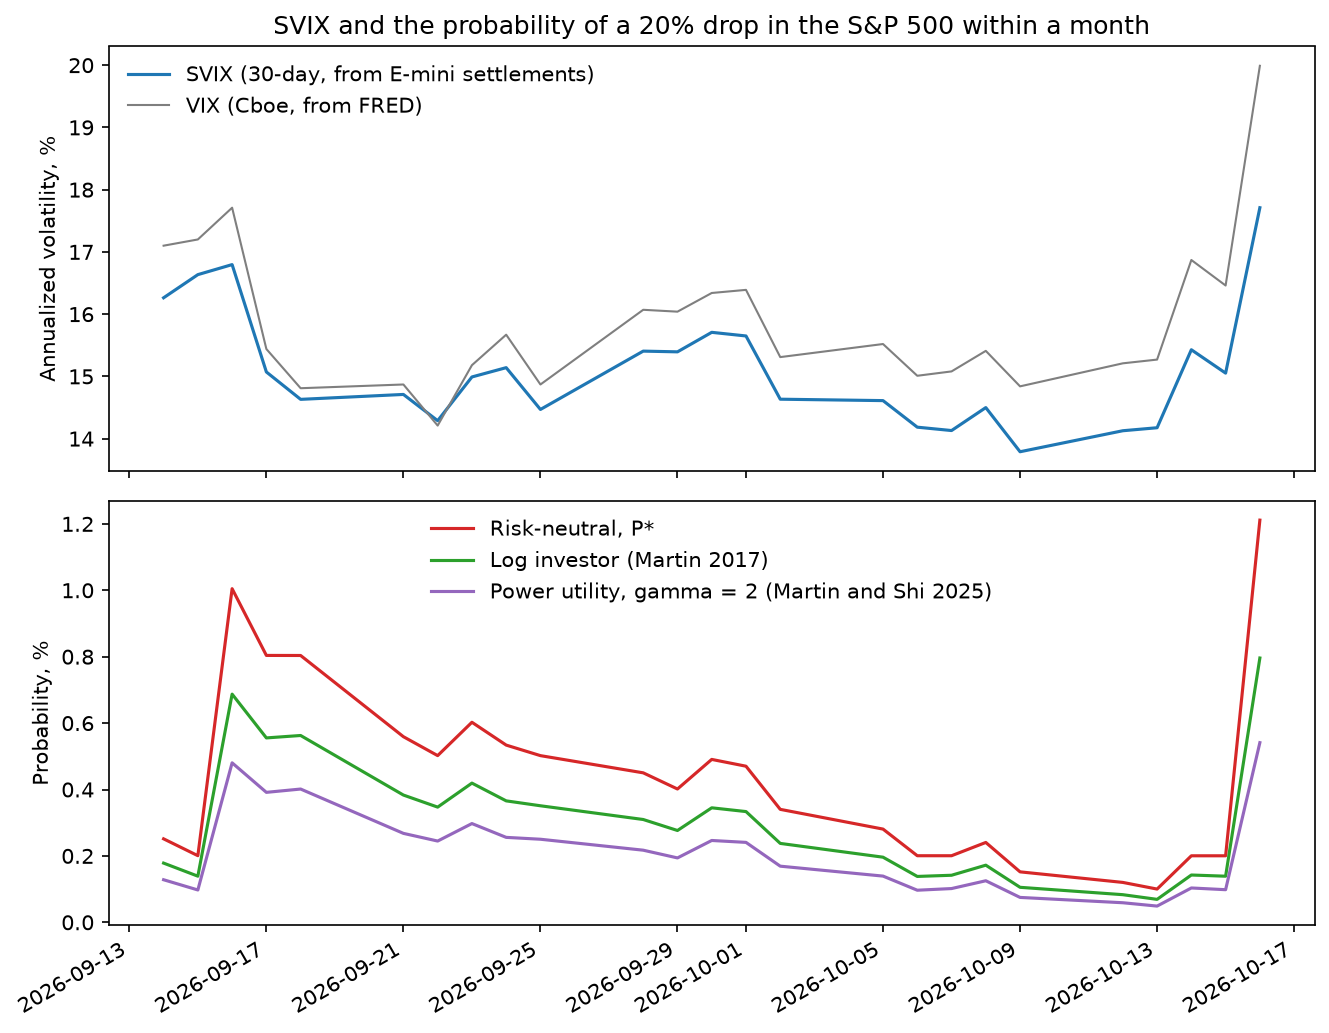

In [3]:
Image(filename=str(OUTPUT_DIR / "svix_monitor.png"))

The same chart, interactive, is the site's chart page, built by
`src/monitor_chart.py` from this history.

SVIX sits a little below the VIX. Both are annualized volatilities read
off the same options, but the VIX weights each strike by $1/K^2$ and
SVIX weights them equally, so the VIX leans harder on the put wing; the
gap is a measure of how steep the smirk is. The probabilities move with
the smile too, and the risk-neutral one is always the largest: it charges
for crash states at their marginal utility.

## What the workflow does

`uv run doit monitor` is the whole update. The task re-pulls the trailing
window (cheap: a session is 19 MB and $0.00), computes the rows for the
sessions the history does not have yet, appends them, and redraws the
charts. Run it on your laptop and it does the same thing. The workflow
adds the parts that make it unattended:

1. **A schedule.** `on: schedule: cron: '30 14 * * *'`, every day at
   14:30 UTC, after CME's final settlements of the previous evening have
   reached Databento. GitHub's cron runs in UTC; the five fields are
   minute, hour, day of month, month, day of week.
2. **A secret.** The pull needs your Databento key. It lives in the
   repository's secret store (Settings → Secrets and variables → Actions)
   and reaches the step as `${{ secrets.DATABENTO_API_KEY }}`. It is never
   in the file, never in a commit, never in the log.
3. **An environment.** `astral-sh/setup-uv` installs `uv`; `uv run doit`
   then installs Python 3.12 and the locked dependencies from `uv.lock`,
   the same versions as on your laptop.
4. **A commit.** The updated history is committed back to `main` by the
   workflow itself, with `[skip ci]` in the message so that the push does
   not start the workflow again.
5. **A deploy.** The built `docs/` folder is force-pushed as a single
   orphan commit on the `gh-pages` branch, which GitHub Pages serves.

Two places it goes wrong, in our experience. A push to `main` without
`[skip ci]` retriggers the workflow, which pushes again, forever. And a
deploy that does not `git clean -fdx` first carries `_data/` and `.venv/`
into the published site.

## Why the history is a tracked file

Everything else the pipeline produces is regenerated from source: pull
again, compute again, same answer. The history is different. Each row
costs a session's pull, and a year of them would cost a year of pulls, so
the monitor keeps what it has computed in `data_manual/svix_monitor_history.csv`
and the workflow commits it. The first rows were computed once, when the
repository was built, from a pull of the trailing weeks; every row after
that was added by a morning run. If the pipeline's engine changes, the
history can be rebuilt from a longer pull; until then it is the record.

In [4]:
latest = history.iloc[-1]
HTML(
    f"<p>As of <b>{latest['date']:%A, %B %d, %Y}</b>: SVIX {latest['svix_30']:.1f}, VIX {latest['vix']:.1f}; "
    f"the options market prices a 20% drop over the next {int(latest['days_used'])} days at "
    f"<b>{100 * latest['p_star_20']:.2f}%</b> risk-neutral, which a log investor who holds the market reads as "
    f"<b>{100 * latest['p_log_20']:.2f}%</b>.</p>"
)